In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [21]:
data_path="/Users/mo7ammedsharaki/programming/DATA QUEST/Population-Growth-Migration-and-Urban-Pressure/2026 ASA DataQuest/WPP2024_Demographic_Indicators_Medium_csv.gz"
df=pd.read_csv(data_path,compression="gzip",
                 encoding="utf-8-sig",
                 low_memory=False)
# df=pd.DataFrame(data)
df.columns

# data["TPopulation1Jan"]


Index(['SortOrder', 'LocID', 'Notes', 'ISO3_code', 'ISO2_code', 'SDMX_code',
       'LocTypeID', 'LocTypeName', 'ParentID', 'Location', 'VarID', 'Variant',
       'Time', 'TPopulation1Jan', 'TPopulation1July', 'TPopulationMale1July',
       'TPopulationFemale1July', 'PopDensity', 'PopSexRatio', 'MedianAgePop',
       'NatChange', 'NatChangeRT', 'PopChange', 'PopGrowthRate',
       'DoublingTime', 'Births', 'Births1519', 'CBR', 'TFR', 'NRR', 'MAC',
       'SRB', 'Deaths', 'DeathsMale', 'DeathsFemale', 'CDR', 'LEx', 'LExMale',
       'LExFemale', 'LE15', 'LE15Male', 'LE15Female', 'LE65', 'LE65Male',
       'LE65Female', 'LE80', 'LE80Male', 'LE80Female', 'InfantDeaths', 'IMR',
       'LBsurvivingAge1', 'Under5Deaths', 'Q5', 'Q0040', 'Q0040Male',
       'Q0040Female', 'Q0060', 'Q0060Male', 'Q0060Female', 'Q1550',
       'Q1550Male', 'Q1550Female', 'Q1560', 'Q1560Male', 'Q1560Female',
       'NetMigrations', 'CNMR'],
      dtype='object')

In [22]:
data_path="/Users/mo7ammedsharaki/programming/DATA QUEST/Population-Growth-Migration-and-Urban-Pressure/2026 ASA DataQuest/WPP2024_Demographic_Indicators_Medium_csv.gz"
data=pd.read_csv(data_path,compression="gzip",
                 encoding="utf-8-sig",
                 low_memory=False)
# df=pd.DataFrame(data)
data.columns

# data["TPopulation1Jan"]


Index(['SortOrder', 'LocID', 'Notes', 'ISO3_code', 'ISO2_code', 'SDMX_code',
       'LocTypeID', 'LocTypeName', 'ParentID', 'Location', 'VarID', 'Variant',
       'Time', 'TPopulation1Jan', 'TPopulation1July', 'TPopulationMale1July',
       'TPopulationFemale1July', 'PopDensity', 'PopSexRatio', 'MedianAgePop',
       'NatChange', 'NatChangeRT', 'PopChange', 'PopGrowthRate',
       'DoublingTime', 'Births', 'Births1519', 'CBR', 'TFR', 'NRR', 'MAC',
       'SRB', 'Deaths', 'DeathsMale', 'DeathsFemale', 'CDR', 'LEx', 'LExMale',
       'LExFemale', 'LE15', 'LE15Male', 'LE15Female', 'LE65', 'LE65Male',
       'LE65Female', 'LE80', 'LE80Male', 'LE80Female', 'InfantDeaths', 'IMR',
       'LBsurvivingAge1', 'Under5Deaths', 'Q5', 'Q0040', 'Q0040Male',
       'Q0040Female', 'Q0060', 'Q0060Male', 'Q0060Female', 'Q1550',
       'Q1550Male', 'Q1550Female', 'Q1560', 'Q1560Male', 'Q1560Female',
       'NetMigrations', 'CNMR'],
      dtype='object')

Variant
Medium    84360
Name: count, dtype: int64


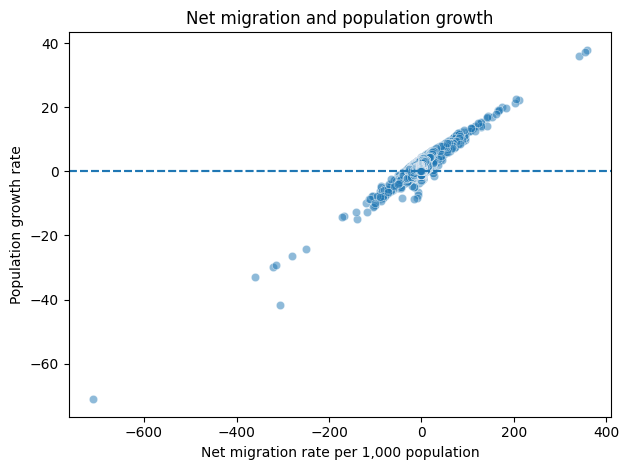

/Users/mo7ammedsharaki/programming/DATA QUEST/Population-Growth-Migration-and-Urban-Pressure/DATA_Env/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/mo7ammedsharaki/programming/DATA QUEST/Population-Growth-Migration-and-Urban-Pressure/DATA_Env/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/mo7ammedsharaki/programming/DATA QUEST/Population-Growth-Migration-and-Urban-Pressure/DATA_Env/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)


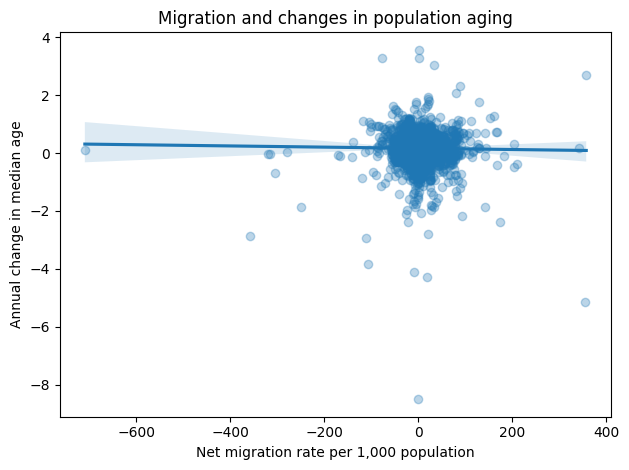

                 CNMR  PopGrowthRate  MedianAgePop  ChangeMedianAge   TFR  \
CNMR             1.00           0.68          0.07            -0.01 -0.05   
PopGrowthRate    0.68           1.00         -0.64            -0.16  0.60   
MedianAgePop     0.07          -0.64          1.00             0.13 -0.79   
ChangeMedianAge -0.01          -0.16          0.13             1.00 -0.41   
TFR             -0.05           0.60         -0.79            -0.41  1.00   
NatChangeRT     -0.04           0.70         -0.95            -0.20  0.87   

                 NatChangeRT  
CNMR                   -0.04  
PopGrowthRate           0.70  
MedianAgePop           -0.95  
ChangeMedianAge        -0.20  
TFR                     0.87  
NatChangeRT             1.00  


In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

# Now call axhline on plt, not matplotlib_inline

# Keep one consistent scenario for the analysis.
print(data["Variant"].value_counts(dropna=False))

# Use the baseline/medium variant only if that is
# the appropriate label in your dataset.
# Check the actual labels before filtering.
data = data.copy()

# Convert key columns to numeric.
cols = [
    "Time", "CNMR", "NetMigrations", "MedianAgePop",
    "PopGrowthRate", "NatChangeRT", "TFR"
]

for col in cols:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Retain one observation per location and year.
data = data.dropna(
    subset=["ISO3_code", "Time", "MedianAgePop", "CNMR"]
)

data = data.sort_values(["ISO3_code", "Time"])

# Calculate annual changes in median age.
data["ChangeMedianAge"] = (
    data.groupby("ISO3_code")["MedianAgePop"].diff()
)

# Explore migration and population growth.
sns.scatterplot(
    data=data,
    x="CNMR",
    y="PopGrowthRate",
    alpha=0.5
)

plt.axhline(0, linestyle="--")
plt.axhline(0, linestyle="--")
plt.xlabel("Net migration rate per 1,000 population")
plt.ylabel("Population growth rate")
plt.title("Net migration and population growth")
plt.tight_layout()
plt.show()

# Explore migration and annual changes in median age.
sns.regplot(
    data=data,
    x="CNMR",
    y="ChangeMedianAge",
    scatter_kws={"alpha": 0.3}
)

plt.xlabel("Net migration rate per 1,000 population")
plt.ylabel("Annual change in median age")
plt.title("Migration and changes in population aging")
plt.tight_layout()
plt.show()

# Check the correlations among the key variables.
print(
    data[[
        "CNMR", "PopGrowthRate", "MedianAgePop",
        "ChangeMedianAge", "TFR", "NatChangeRT"
    ]].corr().round(2)
)


In [24]:

import pandas as pd
import numpy as np

# Load the demographic data
demo = data.copy()

# Convert numeric fields
numeric_cols = [
    "Time",
    "TPopulation1July",
    "PopGrowthRate",
    "NetMigrations",
    "CNMR",
    "PopDensity",
    "NatChangeRT",
    "MedianAgePop",
    "TFR",
]

for col in numeric_cols:
    demo[col] = pd.to_numeric(demo[col], errors="coerce")

# Inspect data coverage and population variants
print(demo["Variant"].value_counts(dropna=False))
print(demo["LocTypeName"].value_counts(dropna=False))
print(demo["Time"].min(), demo["Time"].max())

# Keep only country-level rows after checking LocTypeName.
# Adapt this filter to the actual labels in your dataset.
demo = demo.dropna(subset=["ISO3_code", "Time"])

# Select one consistent historical series.
# Inspect Variant labels before applying a filter.
# Do not mix projections with historical observations.

demo = demo.sort_values(["ISO3_code", "Time"])

# Calculate annual change in population size as a check.
demo["population_change_pct"] = (
    demo.groupby(["ISO3_code", "Variant"])["TPopulation1July"]
        .pct_change() * 100
)

# Suppose rent contains:
# ISO3_code, year, rent_index
rent = datas.copy()
rent["year"] = pd.to_numeric(rent["year"], errors="coerce")
rent["rent_index"] = pd.to_numeric(
    rent["rent_index"], errors="coerce"
)

rent = rent.sort_values(["ISO3_code", "year"])

# Year-over-year rent-index growth
rent["rent_growth_yoy"] = (
    rent.groupby("ISO3_code")["rent_index"]
        .pct_change() * 100
)

# Merge on country and year, after verifying compatible
# definitions, time periods, and units.
demo = demo.rename(columns={"Time": "year"})

panel = demo.merge(
    rent[["ISO3_code", "year", "rent_index", "rent_growth_yoy"]],
    on=["ISO3_code", "year"],
    how="inner",
    validate="many_to_one"
)

print("Countries:", panel["ISO3_code"].nunique())
print("Observations:", len(panel))
print("Year range:", panel["year"].min(), panel["year"].max())
print(panel[["rent_growth_yoy", "PopGrowthRate", "CNMR"]].isna().mean())


Variant
Medium    35787
Name: count, dtype: int64
LocTypeName
Country/Area    35787
Name: count, dtype: int64
1950 2100


NameError: name 'datas' is not defined

In [25]:

# 1. Which geographical units are included?
print(df["LocTypeName"].value_counts(dropna=False))

# 2. Which locations are included?
print(df[["Location", "ISO3_code"]]
      .drop_duplicates()
      .head(30))

# 3. What time period does the data cover?
print(df["Time"].min(), df["Time"].max())

# 4. Are there multiple population scenarios?
print(df["Variant"].value_counts(dropna=False))

# 5. How complete are the main demographic variables?
cols = [
    "PopGrowthRate",
    "NetMigrations",
    "CNMR",
    "PopDensity",
    "NatChangeRT",
    "MedianAgePop"
]

print(df[cols].isna().mean().sort_values())


LocTypeName
Country/Area         36024
NaN                  35568
Ad Hoc groups         3496
Subregion             3192
SDG region            1368
Income group          1368
Development group     1064
Special other         1064
Geographic region     1064
World                  152
Name: count, dtype: int64
                                               Location ISO3_code
0                     ADB region: Central and West Asia       NaN
152                               ADB region: Developed       NaN
304                               ADB region: East Asia       NaN
456                              ADB region: South Asia       NaN
608                          ADB region: Southeast Asia       NaN
760                             ADB region: The Pacific       NaN
912                                               AUKUS       NaN
1064                                      African Group       NaN
1216                                      African Union       NaN
1368                      Africa